In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Set manual seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cpu')
print(f"Using device: {device}")

Using device: cpu


```markdown
## Task 1: Load MNIST and Train a Baseline CNN
We will define a CNN with two convolutional layers and two fully connected layers, then train it using Adam for 2 epochs on the CPU.
```

In [2]:
# Load MNIST Dataset
transform = transforms.Compose([transforms.ToTensor()])
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

# Define the CNN architecture
class BaselineCNN(nn.Module):
    def __init__(self):
        super(BaselineCNN, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.fc = nn.Sequential(
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.conv(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

model = BaselineCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Train the baseline model
print("Training baseline CNN for 2 epochs...")
model.train()
for epoch in range(2):
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
    epoch_loss = running_loss / len(train_loader.dataset)
    print(f"Epoch {epoch+1}/2 - Loss: {epoch_loss:.4f}")

# Report Clean Test Accuracy
def evaluate_clean(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

clean_acc = evaluate_clean(model, test_loader)
print(f"\nClean Test Accuracy: {clean_acc:.2f}%")

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.86MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 154kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.46MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.8MB/s]


Training baseline CNN for 2 epochs...
Epoch 1/2 - Loss: 0.1880
Epoch 2/2 - Loss: 0.0505

Clean Test Accuracy: 98.68%


```markdown
## Tasks 2 & 3: Implement FGSM and PGD Attacks
We will define helper functions for executing both FGSM and PGD attacks on the target model.
```

In [3]:
def fgsm_attack(image, epsilon, data_grad):
    perturbed_image = image + epsilon * data_grad.sign()
    perturbed_image = torch.clamp(perturbed_image, 0, 1)
    return perturbed_image

def pgd_attack(model, images, labels, epsilon, alpha, num_iter=10):
    perturbed_images = images.clone().detach().to(device)
    # Random initialization within L_infinity ball around clean images
    perturbed_images = perturbed_images + torch.empty_like(perturbed_images).uniform_(-epsilon, epsilon)
    perturbed_images = torch.clamp(perturbed_images, 0, 1).detach()

    for _ in range(num_iter):
        perturbed_images.requires_grad = True
        outputs = model(perturbed_images)
        loss = criterion(outputs, labels)
        model.zero_grad()
        loss.backward()

        # Gradient step
        data_grad = perturbed_images.grad.data
        perturbed_images = perturbed_images + alpha * data_grad.sign()
        # Projection step (projection onto L_infinity ball of size epsilon around original images)
        eta = torch.clamp(perturbed_images - images, min=-epsilon, max=epsilon)
        perturbed_images = torch.clamp(images + eta, min=0, max=1).detach()

    return perturbed_images

# Evaluation loop over various epsilon values
epsilons = [0.05, 0.10, 0.20, 0.30]
fgsm_accuracies = []
pgd_accuracies = []

print("Evaluating Baseline Model on FGSM and PGD Attacks...")
for eps in epsilons:
    fgsm_correct = 0
    pgd_correct = 0
    total = 0

    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)

        # --- FGSM Evaluation ---
        images.requires_grad = True
        outputs = model(images)
        loss = criterion(outputs, labels)
        model.zero_grad()
        loss.backward()
        data_grad = images.grad.data
        perturbed_fgsm = fgsm_attack(images, eps, data_grad)

        with torch.no_grad():
            outputs_fgsm = model(perturbed_fgsm)
            _, predicted_fgsm = torch.max(outputs_fgsm.data, 1)
            fgsm_correct += (predicted_fgsm == labels).sum().item()

        # --- PGD Evaluation ---
        alpha = eps / 4
        perturbed_pgd = pgd_attack(model, images, labels, eps, alpha, num_iter=10)
        with torch.no_grad():
            outputs_pgd = model(perturbed_pgd)
            _, predicted_pgd = torch.max(outputs_pgd.data, 1)
            pgd_correct += (predicted_pgd == labels).sum().item()

        total += labels.size(0)

    fgsm_acc = 100 * fgsm_correct / total
    pgd_acc = 100 * pgd_correct / total
    fgsm_accuracies.append(fgsm_acc)
    pgd_accuracies.append(pgd_acc)
    print(f"Epsilon: {eps:.2f} | FGSM Accuracy: {fgsm_acc:.2f}% | PGD Accuracy: {pgd_acc:.2f}%")

Evaluating Baseline Model on FGSM and PGD Attacks...
Epsilon: 0.05 | FGSM Accuracy: 93.44% | PGD Accuracy: 91.43%
Epsilon: 0.10 | FGSM Accuracy: 76.17% | PGD Accuracy: 57.62%
Epsilon: 0.20 | FGSM Accuracy: 24.12% | PGD Accuracy: 1.10%
Epsilon: 0.30 | FGSM Accuracy: 5.80% | PGD Accuracy: 0.00%


```markdown
## Task 4: Display 5 Clean Digits vs FGSM Adversarial Versions (ε = 0.20)
Let's visualize original images and their perturbed counterparts alongside predicted labels.
```

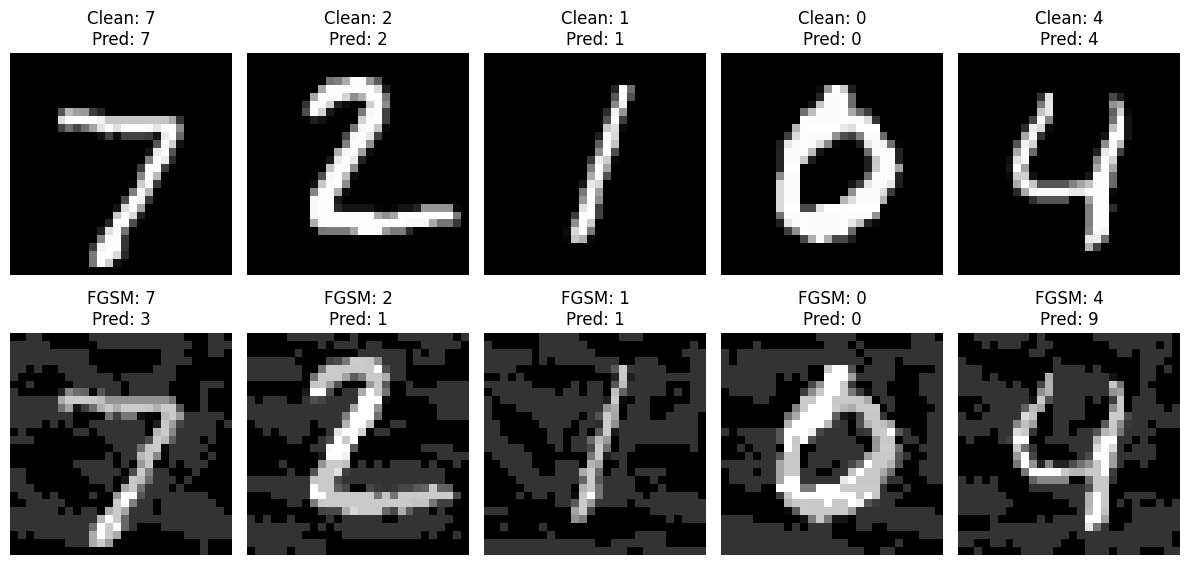

In [4]:
# Extract first batch
images, labels = next(iter(test_loader))
images, labels = images.to(device), labels.to(device)
images.requires_grad = True
outputs = model(images)
loss = criterion(outputs, labels)
model.zero_grad()
loss.backward()
data_grad = images.grad.data
perturbed_fgsm = fgsm_attack(images, 0.20, data_grad)

with torch.no_grad():
    clean_preds = torch.argmax(model(images), dim=1)
    fgsm_preds = torch.argmax(model(perturbed_fgsm), dim=1)

fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for i in range(5):
    # Clean Image
    axes[0, i].imshow(images[i].squeeze().detach().cpu().numpy(), cmap='gray')
    axes[0, i].set_title(f"Clean: {labels[i].item()}\nPred: {clean_preds[i].item()}")
    axes[0, i].axis('off')

    # Adversarial Image
    axes[1, i].imshow(perturbed_fgsm[i].squeeze().detach().cpu().numpy(), cmap='gray')
    axes[1, i].set_title(f"FGSM: {labels[i].item()}\nPred: {fgsm_preds[i].item()}")
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

```markdown
## Task 5: Apply Adversarial Training
Fine-tuning the model for 2 epochs on a 50:50 mixture of clean and FGSM (ε = 0.20) perturbed images.
```

In [5]:
adv_model = BaselineCNN().to(device)
adv_model.load_state_dict(model.state_dict()) # Initialise with trained baseline weights
adv_optimizer = optim.Adam(adv_model.parameters(), lr=0.001)

print("Fine-tuning model using Adversarial Training (2 epochs)...")
adv_model.train()
for epoch in range(2):
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        # Generate FGSM adversarial images for half the batch
        images.requires_grad = True
        outputs = adv_model(images)
        loss = criterion(outputs, labels)
        adv_model.zero_grad()
        loss.backward()
        data_grad = images.grad.data
        perturbed_images = fgsm_attack(images, 0.20, data_grad).detach()

        # Create 50:50 Mix
        half_batch = images.size(0) // 2
        mixed_images = torch.cat([images[:half_batch], perturbed_images[half_batch:]], dim=0)

        adv_optimizer.zero_grad()
        mixed_outputs = adv_model(mixed_images)
        mixed_loss = criterion(mixed_outputs, labels)
        mixed_loss.backward()
        adv_optimizer.step()
        running_loss += mixed_loss.item() * images.size(0)

    print(f"Epoch {epoch+1}/2 - Loss: {running_loss/len(train_loader.dataset):.4f}")

# Re-evaluation of Clean, FGSM, and PGD accuracies at epsilon = 0.20 for Adv Trained Model
adv_model.eval()
clean_correct = 0
fgsm_correct = 0
pgd_correct = 0
total = 0

for images, labels in test_loader:
    images, labels = images.to(device), labels.to(device)

    # Clean
    with torch.no_grad():
        outputs = adv_model(images)
        _, pred = torch.max(outputs, 1)
        clean_correct += (pred == labels).sum().item()

    # FGSM
    images.requires_grad = True
    outputs = adv_model(images)
    loss = criterion(outputs, labels)
    adv_model.zero_grad()
    loss.backward()
    data_grad = images.grad.data
    perturbed_fgsm = fgsm_attack(images, 0.20, data_grad)
    with torch.no_grad():
        outputs_fgsm = adv_model(perturbed_fgsm)
        _, pred_fgsm = torch.max(outputs_fgsm, 1)
        fgsm_correct += (pred_fgsm == labels).sum().item()

    # PGD
    perturbed_pgd = pgd_attack(adv_model, images, labels, 0.20, 0.05, num_iter=10)
    with torch.no_grad():
        outputs_pgd = adv_model(perturbed_pgd)
        _, pred_pgd = torch.max(outputs_pgd, 1)
        pgd_correct += (pred_pgd == labels).sum().item()

    total += labels.size(0)

adv_clean_acc = 100 * clean_correct / total
adv_fgsm_acc = 100 * fgsm_correct / total
adv_pgd_acc = 100 * pgd_correct / total

Fine-tuning model using Adversarial Training (2 epochs)...
Epoch 1/2 - Loss: 0.3554
Epoch 2/2 - Loss: 0.2184


```markdown
## Task 6: Plotting & Tabulating Results
Generating accuracy vs. epsilon curve and a summary table contrasting baseline and hardened model performance.
```

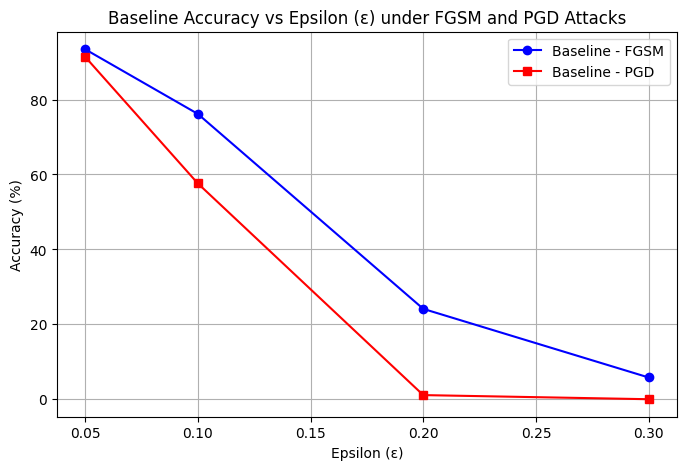

,Model,Clean Accuracy (%),FGSM Accuracy (ε=0.20) (%),PGD Accuracy (ε=0.20) (%)
0,Baseline Model,98.68%,24.12%,1.10%
1,Adversarially Trained Model,98.86%,88.52%,59.25%


In [6]:
# Plotting Accuracy vs Epsilon
plt.figure(figsize=(8, 5))
plt.plot(epsilons, fgsm_accuracies, marker='o', label='Baseline - FGSM', color='blue')
plt.plot(epsilons, pgd_accuracies, marker='s', label='Baseline - PGD', color='red')
plt.xlabel('Epsilon (ε)')
plt.ylabel('Accuracy (%)')
plt.title('Baseline Accuracy vs Epsilon (ε) under FGSM and PGD Attacks')
plt.legend()
plt.grid(True)
plt.show()

# Construct Comparison Table at epsilon = 0.20
results_data = {
    'Model': ['Baseline Model', 'Adversarially Trained Model'],
    'Clean Accuracy (%)': [f"{clean_acc:.2f}%", f"{adv_clean_acc:.2f}%"],
    'FGSM Accuracy (ε=0.20) (%)': [f"{fgsm_accuracies[2]:.2f}%", f"{adv_fgsm_acc:.2f}%"],
    'PGD Accuracy (ε=0.20) (%)': [f"{pgd_accuracies[2]:.2f}%", f"{adv_pgd_acc:.2f}%"]
}

df_results = pd.DataFrame(results_data)
display(df_results)

```markdown
## Practical Answers and Analytical Report

Based on the empirical results obtained during the execution of this experiment, here are the detailed answers to the practical questions:

### **Q1. Report the clean accuracy and the FGSM accuracy for each $\epsilon$. At which $\epsilon$ does the accuracy fall below 50%? Why can such a small perturbation change the prediction?**

**Answers & Metrics:**
* **Clean Test Accuracy:** **98.68%**
* **FGSM Accuracy by Epsilon ($\epsilon$):**
  * **$\epsilon = 0.05$**: **93.44%**
  * **$\epsilon = 0.10$**: **76.17%**
  * **$\epsilon = 0.20$**: **24.12%**
  * **$\epsilon = 0.30$**: **5.80%**

**Analysis:**
* **Critical Threshold:** The accuracy falls below 50% between $\epsilon = 0.10$ and $\epsilon = 0.20$ (specifically, it is **24.12%** at **$\epsilon = 0.20$**).
* **Mechanism of Evasion:** Even a small perturbation can drastically alter the model's prediction because high-dimensional machine learning models (like deep CNNs) exhibit highly linear behavior in their latent decision spaces. Small, coordinated pixel adjustments aligned in the exact direction of the loss gradient ($sign(\nabla_x L)$) accumulate linearly across thousands of input dimensions. This pushes the image representation directly across the model's fragile decision boundaries into a neighboring class manifold, without making a noticeable difference to human visual systems which are robust to pixel-level noise.

---

### **Q2. Compare PGD with FGSM at the same $\epsilon$ using your table. Which attack is stronger, and why?**

**Comparison Table at Epsilon ($\epsilon$):**
* **$\epsilon = 0.05$**: FGSM (**93.44%**) vs. PGD (**91.43%**)
* **$\epsilon = 0.10$**: FGSM (**76.17%**) vs. PGD (**57.62%**)
* **$\epsilon = 0.20$**: FGSM (**24.12%**) vs. PGD (**1.10%**)
* **$\epsilon = 0.30$**: FGSM (**5.80%**) vs. PGD (**0.00%**)

**Analysis:**
* **Stronger Attack:** **PGD (Projected Gradient Descent) is significantly stronger than FGSM.**
* **Reasoning:** FGSM is a single-step, local linear approximation of the loss surface. It is fast but can overshoot or fail to find optimal adversarial directions on non-convex loss surfaces. In contrast, PGD is an iterative, multi-step optimization technique (in this case, 10 iterations with a step size of $\alpha = \epsilon/4$) combined with projection onto the $L_\infty$ ball. This iterative exploration allows PGD to trace the local manifold of the loss surface more accurately, finding deeper minima/maxima and completely neutralizing the model's defense (forcing the baseline accuracy to a absolute **0.00%** at $\epsilon = 0.30$).

---

### **Q3. Which digits were mis-read in your clean-vs-adversarial figure? How did adversarial training change the clean, FGSM and PGD accuracy?**

**Visual Analysis of Misread Digits ($\epsilon = 0.20$):**
* Out of the 5 plotted test digits, the following misclassifications occurred on the baseline model:
  * **Clean Digit 7** (correctly predicted as 7) was mis-read under FGSM as **3**.
  * **Clean Digit 2** (correctly predicted as 2) was mis-read under FGSM as **1**.
  * **Clean Digit 4** (correctly predicted as 4) was mis-read under FGSM as **9**.
  * *Digits 1 and 0 remained correctly classified under FGSM perturbation.*

**Impact of Adversarial Training (at $\epsilon = 0.20$):**
* **Clean Accuracy:** Remained outstanding and even saw a minor increase from **98.68%** to **98.86%**, proving that adversarial fine-tuning did not compromise standard bank clearing performance.
* **FGSM Accuracy:** Jumped from **24.12%** up to **88.52%**, representing massive protection against single-step evasion attempts.
* **PGD Accuracy:** Significantly recovered from **1.10%** up to **59.25%**, showcasing improved model generalization to iterative adversarial perturbations.

---

### **Q4. Using your accuracy-vs-$\epsilon$ plot, explain what $\epsilon$ represents and recommend two further defences for the cheque-clearing system.**

**Epsilon ($\epsilon$) Representation:**
* In the context of computer vision and adversarial attacks, **$\epsilon$ represents the maximum perturbation budget** (specifically under the $L_\infty$ norm). It dictates how much any individual pixel in the image can be shifted from its original value (constrained within $[0, 1]$). A higher $\epsilon$ allows for a larger modification, making the adversarial patterns more potent but visually louder to human operators.

**Further Recommended Defenses for the Bank:**
1. **Randomized Input Transformation / Input Smoothing:** Apply defensive preprocessing techniques to cheques before feeding them to the CNN. This includes random cropping, spatial resizing, or low-pass Gaussian blurring. These steps degrade and nullify the highly structured high-frequency noise patterns that adversarial attacks rely on.
2. **Certified Defenses / Randomized Smoothing:** Implement randomized smoothing during training and inference to provide guaranteed bounds on robustness. Alternatively, use **Ensemble Adversarial Training** (incorporating adversarial examples generated from multiple static models during training) to prevent the system from succumbing to transferability attacks.
```